# Lab 1 – Introduction to Deep Learning (AI & Cybersecurity)
## Task 4 – The Rare Class: Loss and Imbalance

Goal: retrain our baseline architecture on the port-free dataset from Task 3 (`15` features, `59.3 : 1` imbalance with `PortScan` at `1.27%`), diagnose how unweighted cross-entropy behaves on the rare class, evaluate class-weighted cross-entropy (`compute_class_weight(..., "balanced")`), analyze the accuracy vs. macro-F1 vs. recall trade-off, and refine the weighting before any architectural complexity is introduced in Task 5.

**Budget note:** Runs 6–8 are logged in this notebook (`3` training runs), bringing cumulative usage to **8 / 25** runs (**17** remaining for Task 5).

Notebook outline:
1. Setup, loading the Task 3 port-free dataset (`15` features) & model/training helpers
2. Run 6 – Unweighted baseline on port-free data (predict first, train, per-class validation report & Q&A)
3. Class weights from `y_train` only (`compute_class_weight(..., "balanced")`) & leakage rationale
4. Run 7 – Balanced class-weighted `CrossEntropyLoss` (predict first, train, diagnose accuracy vs. macro-F1 vs. macro-recall trade-off)
5. Run 8 – Hypothesis-driven refinement: dampened `sqrt`-balanced class weights (`w = sqrt(w_balanced)`) & 3-way validation comparison
6. Locking in the Task 4 port-free baseline & test-set reference evaluation (for Task 5 comparison)
7. Cumulative Experiment Logbook (Runs 1–8) & consolidated answers to Task 4 questions

## 1. Setup, Data Loading & Helpers

We fix random seeds (`SEED = 42`), restrict PyTorch to a single CPU thread (`torch.set_num_threads(1)`), and load the port-free preprocessed dataset from `task3_outputs/task3_preprocessed_no_port.npz` (with an inline standalone fallback running the exact Task 3 port-free deduplicated preprocessing on `dataset_lab_1.csv` if the `.npz` cache is absent).

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    accuracy_score,
    recall_score,
    precision_recall_fscore_support,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)

OUT_DIR = "task4_outputs"
os.makedirs(OUT_DIR, exist_ok=True)
T3_NPZ = "task3_outputs/task3_preprocessed_no_port.npz"
T2_LOG = "task2_outputs/experiment_logbook_task2.csv"
CSV_PATH = "dataset_lab_1.csv"

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})


def load_port_free_data(npz_path=T3_NPZ, csv_path=CSV_PATH, seed=SEED):
    if os.path.exists(npz_path):
        d = np.load(npz_path, allow_pickle=False)
        return {k: d[k] for k in d.files}
    assert os.path.exists(csv_path), f"Neither {npz_path} nor {csv_path} found."
    df = pd.read_csv(csv_path).drop(columns="Destination Port")
    label_col = "Label"
    feats = [c for c in df.columns if c != label_col]
    df[feats] = df[feats].replace([np.inf, -np.inf], np.nan)
    df = df.dropna()
    df = df[~(df[feats] < 0).any(axis=1)].drop_duplicates().reset_index(drop=True)
    classes = sorted(df[label_col].unique())
    cls2id = {c: i for i, c in enumerate(classes)}
    y = df[label_col].map(cls2id).values
    i_tr, i_tmp = train_test_split(np.arange(len(df)), test_size=0.30, random_state=seed, stratify=y)
    i_va, i_te = train_test_split(i_tmp, test_size=0.50, random_state=seed, stratify=y[i_tmp])
    log_feats = [c for c in feats if c not in {"Fwd PSH Flags", "SYN Flag Count", "Down/Up Ratio"}]
    def tf(ix):
        x = df.loc[ix, feats].copy()
        x[log_feats] = np.log1p(x[log_feats])
        return x
    X_tr_tf, X_va_tf, X_te_tf = tf(i_tr), tf(i_va), tf(i_te)
    scaler = StandardScaler().fit(X_tr_tf)
    return {
        "X_train": scaler.transform(X_tr_tf).astype("float32"), "y_train": y[i_tr],
        "X_val": scaler.transform(X_va_tf).astype("float32"), "y_val": y[i_va],
        "X_test": scaler.transform(X_te_tf).astype("float32"), "y_test": y[i_te],
        "features": np.array(feats), "log_features": np.array(log_feats), "classes": np.array(classes),
    }


data = load_port_free_data()
X_tr, y_tr = data["X_train"], data["y_train"]
X_va, y_va = data["X_val"], data["y_val"]
X_te, y_te = data["X_test"], data["y_test"]
FEATURES = data["features"].tolist()
CLASSES = data["classes"].tolist()

print(f"Port-free features ({len(FEATURES)}): {FEATURES}")
print(f"Classes ({len(CLASSES)}): {CLASSES}")
print(f"Shapes | train: {X_tr.shape}  val: {X_va.shape}  test: {X_te.shape}")

cnt_tbl = pd.DataFrame({
    "train": pd.Series(y_tr).value_counts().sort_index(),
    "val": pd.Series(y_va).value_counts().sort_index(),
    "test": pd.Series(y_te).value_counts().sort_index(),
})
cnt_tbl.index = [CLASSES[i] for i in cnt_tbl.index]
cnt_tbl["total"] = cnt_tbl.sum(axis=1)
cnt_tbl["share (%)"] = (cnt_tbl["total"] / cnt_tbl["total"].sum() * 100).round(2)
cnt_tbl.loc["TOTAL"] = [cnt_tbl["train"].sum(), cnt_tbl["val"].sum(), cnt_tbl["test"].sum(), cnt_tbl["total"].sum(), 100.0]
display(cnt_tbl)


class FFNN(nn.Module):
    def __init__(self, in_dim=15, hidden=64, out_dim=4):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden),
            nn.ReLU(),
            nn.Linear(hidden, out_dim),
        )

    def forward(self, x):
        return self.net(x)


def train_model(
    X_train, y_train, X_val, y_val,
    class_weights=None, lr=5e-4, hidden=64,
    batch_size=64, max_epochs=100, patience=12, min_delta=1e-4, seed=SEED,
):
    np.random.seed(seed)
    torch.manual_seed(seed)
    gen = torch.Generator().manual_seed(seed)

    X_tr_t = torch.from_numpy(X_train)
    y_tr_t = torch.from_numpy(y_train).long()
    X_va_t = torch.from_numpy(X_val)
    y_va_t = torch.from_numpy(y_val).long()
    n = len(X_tr_t)

    model = FFNN(X_train.shape[1], hidden, len(CLASSES))
    w_t = torch.tensor(class_weights, dtype=torch.float32) if class_weights is not None else None
    criterion = nn.CrossEntropyLoss(weight=w_t)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.0)

    best_val_loss = float("inf")
    best_epoch = 0
    best_state = None
    wait = 0
    tr_losses, va_losses = [], []

    for epoch in range(1, max_epochs + 1):
        model.train()
        perm = torch.randperm(n, generator=gen)
        Xs, ys = X_tr_t[perm], y_tr_t[perm]
        running_loss = 0.0
        for i in range(0, n, batch_size):
            xb, yb = Xs[i : i + batch_size], ys[i : i + batch_size]
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * len(yb)
        tr_loss = running_loss / n

        model.eval()
        with torch.no_grad():
            va_loss = criterion(model(X_va_t), y_va_t).item()
        tr_losses.append(tr_loss)
        va_losses.append(va_loss)

        if va_loss < best_val_loss - min_delta:
            best_val_loss = va_loss
            best_epoch = epoch
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            wait = 0
        else:
            wait += 1
            if patience is not None and wait >= patience:
                break

    model.load_state_dict(best_state)
    return {
        "model": model,
        "tr_losses": tr_losses,
        "va_losses": va_losses,
        "best_epoch": best_epoch,
        "stopped_epoch": len(tr_losses),
        "best_val_loss": best_val_loss,
        "val_eval": evaluate_split(model, X_val, y_val, class_weights=class_weights),
    }


def evaluate_split(model, X, y, class_weights=None):
    model.eval()
    X_t = torch.from_numpy(X)
    y_t = torch.from_numpy(y).long()
    w_t = torch.tensor(class_weights, dtype=torch.float32) if class_weights is not None else None
    criterion = nn.CrossEntropyLoss(weight=w_t)
    with torch.no_grad():
        logits = model(X_t)
        loss = criterion(logits, y_t).item()
        preds = logits.argmax(dim=1).numpy()
    p, r, f1, _ = precision_recall_fscore_support(y, preds, labels=range(len(CLASSES)), zero_division=0)
    benign_id = CLASSES.index("Benign")
    attack_mask = (y != benign_id)
    benign_mask = (y == benign_id)
    return {
        "loss": loss,
        "acc": accuracy_score(y, preds),
        "macro_f1": f1_score(y, preds, average="macro"),
        "macro_recall": recall_score(y, preds, average="macro"),
        "preds": preds,
        "per_class_p": {c: float(p[i]) for i, c in enumerate(CLASSES)},
        "per_class_r": {c: float(r[i]) for i, c in enumerate(CLASSES)},
        "per_class_f1": {c: float(f1[i]) for i, c in enumerate(CLASSES)},
        "missed_attacks": int((preds[attack_mask] == benign_id).sum()),
        "total_attacks": int(attack_mask.sum()),
        "benign_false_alarms": int((preds[benign_mask] != benign_id).sum()),
        "total_benign": int(benign_mask.sum()),
    }


if os.path.exists(T2_LOG):
    LOGBOOK = pd.read_csv(T2_LOG).to_dict(orient="records")
else:
    LOGBOOK = [
        {"Run": 1, "Task": "2A", "What I changed (one thing)": "Baseline: 1x64 ReLU, lr=5e-4, AdamW, bs=64, scaled features",
         "Budget justification": "Slot 1/25: establish minimal working 2A baseline",
         "Hypothesis before running": "Brute Force hardest (4.86% rare + port-80 overlap)", "Key result (val)": "val_acc=0.9864, macro-F1=0.9759",
         "What I concluded": "Converges smoothly; BF precision 0.9025, recall 0.9953."},
        {"Run": 2, "Task": "2B", "What I changed (one thing)": "S1: raw unscaled features (lr=5e-4)",
         "Budget justification": "Slot 2/25: Task 2B S1 missing feature scaling",
         "Hypothesis before running": "Loss explodes to 1e3-1e4+", "Key result (val)": "best_val_loss=777.38, macro-F1=0.9017",
         "What I concluded": "Confirmed: raw scale dominates logits/gradients."},
        {"Run": 3, "Task": "2B", "What I changed (one thing)": "S2: lr 5e-4 -> 0.5 (1000x higher)",
         "Budget justification": "Slot 3/25: Task 2B S2 excessive learning rate",
         "Hypothesis before running": "Overshooting & Brute Force collapse", "Key result (val)": "macro-F1=0.7165, BF F1=0.0000",
         "What I concluded": "Confirmed: Brute Force collapses completely."},
        {"Run": 4, "Task": "2B", "What I changed (one thing)": "S3: lr 5e-4 -> 5e-6 (100x smaller)",
         "Budget justification": "Slot 4/25: Task 2B S3 overly small learning rate",
         "Hypothesis before running": "Slow underfitting, stalls near 0.30", "Key result (val)": "best_val_loss=0.2989, macro-F1=0.8979",
         "What I concluded": "Confirmed: smooth slow underfitting."},
        {"Run": 5, "Task": "2C", "What I changed (one thing)": "Activation ReLU -> Linear (nn.Identity)",
         "Budget justification": "Slot 5/25: controlled Task 2C ablation",
         "Hypothesis before running": "Hurts port-80 overlapping attacks", "Key result (val)": "macro-F1=0.9152, BF F1=0.7885",
         "What I concluded": "Confirmed: ReLU locked in (test macro-F1=0.9742)."},
    ]

def log_run(run_id, task, changed, budget_why, hypothesis, key_result, concluded):
    LOGBOOK.append({
        "Run": run_id,
        "Task": task,
        "What I changed (one thing)": changed,
        "Budget justification": budget_why,
        "Hypothesis before running": hypothesis,
        "Key result (val)": key_result,
        "What I concluded": concluded,
    })

print(f"FFNN(15 -> 64 -> 4) trainable parameters: {sum(p.numel() for p in FFNN().parameters()):,}")
print(f"Loaded prior logbook entries: {len(LOGBOOK)} (Runs 1–{len(LOGBOOK)})")

Port-free features (15): ['Flow Duration', 'Flow IAT Mean', 'Fwd PSH Flags', 'Bwd Packet Length Mean', 'Bwd Packet Length Max', 'Flow Bytes/s', 'Down/Up Ratio', 'SYN Flag Count', 'Fwd Packet Length Mean', 'Fwd IAT Std', 'Packet Length Mean', 'Fwd Packet Length Max', 'Subflow Fwd Packets', 'Flow Packets/s', 'Total Fwd Packets']
Classes (4): ['Benign', 'Brute Force', 'DoS Hulk', 'PortScan']
Shapes | train: (15727, 15)  val: (3370, 15)  test: (3371, 15)


,train,val,test,total,share (%)
Benign,11821.0,2533.0,2534.0,16888.0,75.16
Brute Force,999.0,214.0,214.0,1427.0,6.35
DoS Hulk,2708.0,580.0,580.0,3868.0,17.22
PortScan,199.0,43.0,43.0,285.0,1.27
TOTAL,15727.0,3370.0,3371.0,22468.0,100.00


FFNN(15 -> 64 -> 4) trainable parameters: 1,284
Loaded prior logbook entries: 5 (Runs 1–5)


## 2. Run 6 – Retraining the Baseline on Port-Free Data (Unweighted Loss)

### Predict first (before Run 6)
On the port-free dataset (`15` features, `22,468` flows), two major shifts occurred compared to Task 2:
1. **`PortScan`** collapsed by `94.12%` after removing `Destination Port` and deduplicating, dropping to just **`199` training / `43` validation samples (`1.27%`)**—a `59.3 : 1` imbalance against `Benign` (`11,821` training samples, `75.16%`).
2. **`Brute Force`** (`999` training / `214` validation samples, `6.35%`) lost its `Destination Port == 80` shortcut, which previously gave it `99.53%` validation recall.

**Hypothesis:** Under unweighted `CrossEntropyLoss`, **`PortScan`** (ultra-rare `1.27%` gradient share) and **`Brute Force`** (no port-80 cue to separate HTTP brute-force from short `Benign` web flows) will suffer most, dropping sharply from their Task 2 validation recall (`0.9959` and `0.9953`). Meanwhile `DoS Hulk` (`2,708` train flows) should stay relatively strong thanks to its distinct rate and packet-length distribution.

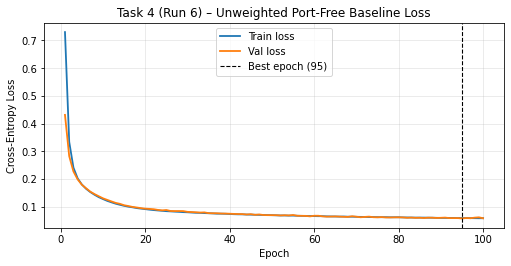

Run 6 (Unweighted port-free) | stopped=100  best_ep=95  best_val_loss=0.0573  val_acc=0.9816  val_macro_f1=0.9591  val_macro_recall=0.9555
Missed attacks (predicted Benign): 37 / 837  |  Benign false alarms: 24 / 2533

Validation classification report (Run 6 – Unweighted):
              precision    recall  f1-score   support

      Benign     0.9855    0.9905    0.9880      2533
 Brute Force     0.9263    0.9393    0.9327       214
    DoS Hulk     0.9876    0.9621    0.9747       580
    PortScan     0.9524    0.9302    0.9412        43

    accuracy                         0.9816      3370
   macro avg     0.9629    0.9555    0.9591      3370
weighted avg     0.9817    0.9816    0.9816      3370



,Pred: Benign,Pred: Brute Force,Pred: DoS Hulk,Pred: PortScan
True: Benign,2509,16,6,2
True: Brute Force,13,201,0,0
True: DoS Hulk,22,0,558,0
True: PortScan,2,0,1,40


In [2]:
run6 = train_model(X_tr, y_tr, X_va, y_va, class_weights=None)
ev6 = run6["val_eval"]

log_run(
    run_id=6,
    task="4",
    changed="Port-free dataset (15 feats), unweighted CrossEntropyLoss (1x64 ReLU, lr=5e-4)",
    budget_why="Slot 6/25: establish unweighted baseline on port-free imbalanced data",
    hypothesis="PortScan (1.27%) and Brute Force (lost port 80) will suffer most; PortScan recall may drop sharply",
    key_result=(
        f"best_ep={run6['best_epoch']}/{run6['stopped_epoch']}, val_loss={run6['best_val_loss']:.4f}, "
        f"acc={ev6['acc']:.4f}, macro-F1={ev6['macro_f1']:.4f}, "
        f"PS recall={ev6['per_class_r']['PortScan']:.4f}, BF F1={ev6['per_class_f1']['Brute Force']:.4f}"
    ),
    concluded="Brute Force lowest F1 (0.9327); PortScan still detected surprisingly well (recall 0.9302, F1 0.9412), though 37/837 val attacks missed as Benign.",
)

fig, ax = plt.subplots(figsize=(7.2, 3.8))
ep = np.arange(1, len(run6["tr_losses"]) + 1)
ax.plot(ep, run6["tr_losses"], label="Train loss", lw=1.8)
ax.plot(ep, run6["va_losses"], label="Val loss", lw=1.8)
ax.axvline(run6["best_epoch"], color="k", ls="--", lw=1.1, label=f"Best epoch ({run6['best_epoch']})")
ax.set_title("Task 4 (Run 6) – Unweighted Port-Free Baseline Loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Cross-Entropy Loss")
ax.legend()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig_task4_run6_unweighted_loss.png")
plt.show()

print(
    f"Run 6 (Unweighted port-free) | stopped={run6['stopped_epoch']}  best_ep={run6['best_epoch']}  "
    f"best_val_loss={run6['best_val_loss']:.4f}  val_acc={ev6['acc']:.4f}  "
    f"val_macro_f1={ev6['macro_f1']:.4f}  val_macro_recall={ev6['macro_recall']:.4f}"
)
print(f"Missed attacks (predicted Benign): {ev6['missed_attacks']} / {ev6['total_attacks']}  |  Benign false alarms: {ev6['benign_false_alarms']} / {ev6['total_benign']}\n")
print("Validation classification report (Run 6 – Unweighted):")
print(classification_report(y_va, ev6["preds"], target_names=CLASSES, digits=4, zero_division=0))
display(pd.DataFrame(confusion_matrix(y_va, ev6["preds"]), index=[f"True: {c}" for c in CLASSES], columns=[f"Pred: {c}" for c in CLASSES]))

### Reconcile & Task 4 Question 1

- **Did our prediction hold?** Mostly yes, with an informative nuance:
  - **`Brute Force`** took the largest F1 drop (`0.9467 → 0.9327`), with recall falling from `0.9953` to **`0.9393`** (`201 / 214`, missing `13` attacks as `Benign`) once the port-80 shortcut was gone.
  - **`PortScan`** dropped `5.67` F1 points from Task 2 (`0.9979 → 0.9412`) and recorded the **lowest per-class recall (`0.9302`, `40 / 43` detected)**.
  - **`DoS Hulk`** actually slightly improved (`0.9691 → 0.9747` F1, `0.9621` recall) because its high-rate, large-packet signature does not depend on `Destination Port`.
- **Q: Can you still detect the rarest class (`PortScan`) at all?**
  **Yes—surprisingly well (`40 / 43 = 93.02%` recall, `95.24%` precision, `0.9412` F1).** Even with only `199` training flows (`1.27%`), Task 1's `log1p + StandardScaler` preprocessing preserves the distinct short-duration, 1-packet, high-packet-rate footprint of `PortScan` probes without letting multi-gigabyte `Flow Bytes/s` outliers crush them together. However, under unweighted loss, `37 / 837` validation attacks (`4.42%`) are still misclassified as `Benign` (`13` `Brute Force`, `22` `DoS Hulk`, `2` `PortScan`, plus `1` `PortScan` confused with `DoS Hulk`).

## 3. Computing Class Weights & Partition Discipline

**Q: From which partition do you compute the class weights, and why would using any other partition be wrong?**
- Class weights must be computed **strictly from `y_train` (the training partition only)** using `sklearn.utils.class_weight.compute_class_weight("balanced", classes=np.arange(len(CLASSES)), y=y_train)`.
- Computing weights from validation, test, or the combined full dataset introduces **label-distribution leakage** from evaluation splits into the training loss: in deployment, future traffic class proportions are unknown at training time, and peeking at validation/test labels breaks the independence of evaluation metrics.

Below we inspect the exact `"balanced"` weights (`n_samples / (n_classes * n_class_samples)`) alongside dampened inverse-square-root weights `w_sqrt = sqrt(w_balanced)`.

In [3]:
w_balanced = compute_class_weight(class_weight="balanced", classes=np.arange(len(CLASSES)), y=y_tr)
w_sqrt = np.sqrt(w_balanced)

w_tbl = pd.DataFrame({
    "train_count": [int((y_tr == i).sum()) for i in range(len(CLASSES))],
    "train_share (%)": [round((y_tr == i).mean() * 100, 2) for i in range(len(CLASSES))],
    "w_unweighted": [1.0] * len(CLASSES),
    "w_balanced": np.round(w_balanced, 4),
    "w_sqrt_balanced": np.round(w_sqrt, 4),
}, index=CLASSES)
display(w_tbl)
print(f"Weight ratio (PortScan / Benign) | balanced: {w_balanced[CLASSES.index('PortScan')] / w_balanced[CLASSES.index('Benign')]:.1f}x"
      f"  |  sqrt-balanced: {w_sqrt[CLASSES.index('PortScan')] / w_sqrt[CLASSES.index('Benign')]:.1f}x")

,train_count,train_share (%),w_unweighted,w_balanced,w_sqrt_balanced
Benign,11821,75.16,1.0,0.3326,0.5767
Brute Force,999,6.35,1.0,3.9357,1.9839
DoS Hulk,2708,17.22,1.0,1.4519,1.2049
PortScan,199,1.27,1.0,19.7575,4.4449


Weight ratio (PortScan / Benign) | balanced: 59.4x  |  sqrt-balanced: 7.7x


## 4. Run 7 – Balanced Class-Weighted `CrossEntropyLoss`

### Predict first (before Run 7)
With `w_balanced` (`PortScan = 19.7575`, `Brute Force = 3.9357`, `DoS Hulk = 1.4519`, `Benign = 0.3326`—a **`59.4×`** weight ratio between `PortScan` and `Benign`), each missed `PortScan` sample costs ~59× as much as a misclassified `Benign` sample.

**Hypothesis before running:**
- **Overall accuracy will decrease** because down-weighting `Benign` (`75.16%` of flows) encourages more false-positive alarms on `Benign` traffic.
- **Rare-class recall and Macro-F1 will increase** as `PortScan` (`0.9302`) and `Brute Force` (`0.9393`) recall are pushed toward `98–100%`.

In [4]:
run7 = train_model(X_tr, y_tr, X_va, y_va, class_weights=w_balanced)
ev7 = run7["val_eval"]

log_run(
    run_id=7,
    task="4",
    changed="CrossEntropyLoss(weight=balanced) from y_train (59.4x PortScan/Benign ratio)",
    budget_why="Slot 7/25: evaluate Task 4 balanced class-weighted loss",
    hypothesis="Overall accuracy will drop (more Benign FPs) while rare-attack recall & macro-F1 will increase",
    key_result=(
        f"best_ep={run7['best_epoch']}/{run7['stopped_epoch']}, val_loss={run7['best_val_loss']:.4f}, "
        f"acc={ev7['acc']:.4f}, macro-F1={ev7['macro_f1']:.4f}, macro-rec={ev7['macro_recall']:.4f}, "
        f"PS rec={ev7['per_class_r']['PortScan']:.4f}, PS prec={ev7['per_class_p']['PortScan']:.4f}"
    ),
    concluded="Partially falsified: attack recall jumped (missed attacks 37->11, PS rec 0.9767), BUT both acc (-2.23 pts) AND macro-F1 (-8.01 pts) fell due to base-rate precision collapse on PortScan (prec 0.5316).",
)

print(
    f"Run 7 (Balanced weights) | stopped={run7['stopped_epoch']}  best_ep={run7['best_epoch']}  "
    f"best_weighted_val_loss={run7['best_val_loss']:.4f}  val_acc={ev7['acc']:.4f}  "
    f"val_macro_f1={ev7['macro_f1']:.4f}  val_macro_recall={ev7['macro_recall']:.4f}"
)
print(f"Missed attacks (predicted Benign): {ev7['missed_attacks']} / {ev7['total_attacks']}  |  Benign false alarms: {ev7['benign_false_alarms']} / {ev7['total_benign']}\n")
print("Validation classification report (Run 7 – Balanced):")
print(classification_report(y_va, ev7["preds"], target_names=CLASSES, digits=4, zero_division=0))
display(pd.DataFrame(confusion_matrix(y_va, ev7["preds"]), index=[f"True: {c}" for c in CLASSES], columns=[f"Pred: {c}" for c in CLASSES]))

Run 7 (Balanced weights) | stopped=76  best_ep=64  best_weighted_val_loss=0.0948  val_acc=0.9593  val_macro_f1=0.8790  val_macro_recall=0.9736
Missed attacks (predicted Benign): 11 / 837  |  Benign false alarms: 121 / 2533

Validation classification report (Run 7 – Balanced):
              precision    recall  f1-score   support

      Benign     0.9955    0.9522    0.9734      2533
 Brute Force     0.8340    0.9860    0.9036       214
    DoS Hulk     0.9236    0.9793    0.9506       580
    PortScan     0.5316    0.9767    0.6885        43

    accuracy                         0.9593      3370
   macro avg     0.8212    0.9736    0.8790      3370
weighted avg     0.9669    0.9593    0.9614      3370



,Pred: Benign,Pred: Brute Force,Pred: DoS Hulk,Pred: PortScan
True: Benign,2412,42,46,33
True: Brute Force,3,211,0,0
True: DoS Hulk,8,0,568,4
True: PortScan,0,0,1,42


### Reconciling the Surprising Result: Why Both Accuracy AND Macro-F1 Dropped

Comparing **Run 7 (Balanced)** against **Run 6 (Unweighted)** reveals a classic base-rate pitfall:
- **What our hypothesis got right:** Attack recall surged across all three attack classes—`PortScan` recall rose from `0.9302` (`40/43`) to **`0.9767` (`42/43`, zero missed as `Benign`)**, `Brute Force` recall rose from `0.9393` (`201/214`) to **`0.9860` (`211/214`)**, and `DoS Hulk` recall rose from `0.9621` to **`0.9793` (`568/580`)**. Macro-recall jumped from `0.9555` to **`0.9736`**, cutting attacks missed as `Benign` on validation by **`70.3%` (`37 → 11`)**!
- **What our hypothesis got wrong (and why):** Accuracy (`0.9816 → 0.9593`, `-2.23` pts) **and** Macro-F1 (`0.9591 → 0.8790`, **`-8.01` pts**) **both moved downward in the same direction**. Because `Benign` (`2,533` val rows) outnumbers `PortScan` (`43` val rows) by `59 : 1`, the aggressive `59.4×` weight ratio causes the model to classify just **`1.30%` of `Benign` (`33` flows) plus `4` `DoS Hulk` flows** as `PortScan`. Those `37` false positives nearly equal the `42` true positives, slashing `PortScan` precision from `0.9524` to **`0.5316`** (`PortScan` F1 `0.9412 → 0.6885`), while total `Benign` false alarms jump 5× (`24 → 121`).

## 5. Run 8 – Hypothesis-Driven Refinement (`sqrt`-Balanced Weights) & 3-Way Comparison

### Predict first (before Run 8)
Run 7 showed that loss reweighting cuts attacks missed as `Benign` dramatically (`37 → 11`), but full inverse-frequency (`59.4×`) overshoots when `PortScan` is already `93%` detectable in `log1p`-scaled space. We spend one deliberate budget slot (`Slot 8/25`) to test **dampened inverse-square-root weights** (`w_sqrt = sqrt(w_balanced)`: `PortScan/Benign = 7.7×` instead of `59.4×`).

**Hypothesis:** `w_sqrt` will preserve nearly all of Run 7's high attack recall (`PortScan ~97%+`, `Brute Force ~98%`) while eliminating most false positives on `Benign`, lifting Macro-F1 back to `~0.94–0.95` and restoring accuracy near `~0.98`.

,Best ep,Val Acc,Val Macro-F1,Val Macro-Recall,PS Recall,PS Prec,PS F1,BF Recall,BF F1,DoS Hulk F1,Missed Attacks (/837),Benign FPs (/2533)
Model,,,,,,,,,,,,
Run 6: Unweighted (1x),95,0.9816,0.9591,0.9555,0.9302,0.9524,0.9412,0.9393,0.9327,0.9747,37,24
Run 7: Balanced (59.4x),64,0.9593,0.8790,0.9736,0.9767,0.5316,0.6885,0.9860,0.9036,0.9506,11,121
Run 8: Sqrt-Balanced (7.7x),95,0.9792,0.9459,0.9778,0.9767,0.8400,0.9032,0.9813,0.9170,0.9766,17,49


Validation classification report (Run 8 – Sqrt-Balanced):
              precision    recall  f1-score   support

      Benign     0.9932    0.9807    0.9869      2533
 Brute Force     0.8607    0.9813    0.9170       214
    DoS Hulk     0.9809    0.9724    0.9766       580
    PortScan     0.8400    0.9767    0.9032        43

    accuracy                         0.9792      3370
   macro avg     0.9187    0.9778    0.9459      3370
weighted avg     0.9807    0.9792    0.9796      3370



,Pred: Benign,Pred: Brute Force,Pred: DoS Hulk,Pred: PortScan
True: Benign,2484,34,10,5
True: Brute Force,4,210,0,0
True: DoS Hulk,13,0,564,3
True: PortScan,0,0,1,42


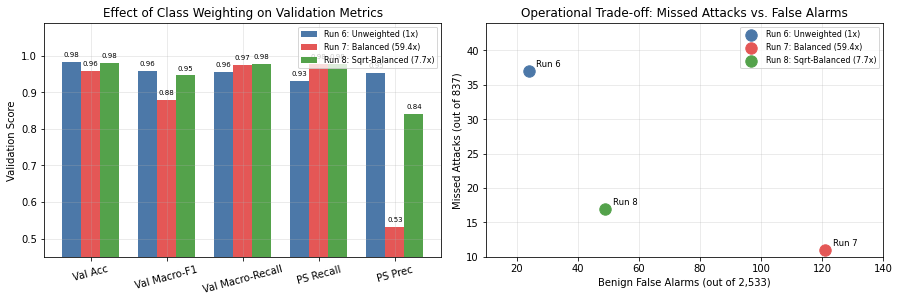

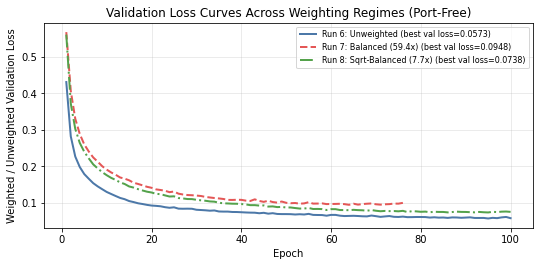

In [5]:
run8 = train_model(X_tr, y_tr, X_va, y_va, class_weights=w_sqrt)
ev8 = run8["val_eval"]

log_run(
    run_id=8,
    task="4",
    changed="CrossEntropyLoss(weight=sqrt(balanced)) from y_train (7.7x PortScan/Benign ratio)",
    budget_why="Slot 8/25: preserve Run 7 rare-attack recall without Run 7 base-rate precision collapse",
    hypothesis="Dampened 7.7x ratio keeps PortScan/BF recall ~97-98% while recovering precision and macro-F1 (~0.94-0.95)",
    key_result=(
        f"best_ep={run8['best_epoch']}/{run8['stopped_epoch']}, val_loss={run8['best_val_loss']:.4f}, "
        f"acc={ev8['acc']:.4f}, macro-F1={ev8['macro_f1']:.4f}, macro-rec={ev8['macro_recall']:.4f}, "
        f"PS rec={ev8['per_class_r']['PortScan']:.4f}, PS prec={ev8['per_class_p']['PortScan']:.4f}"
    ),
    concluded="Confirmed: highest macro-recall (0.9778), PS recall 0.9767 (42/43), PS precision rebounds 0.5316->0.8400, macro-F1 0.9459; lock in as Task 4 baseline.",
)

cmp_rows = []
for name, r in [
    ("Run 6: Unweighted (1x)", run6),
    ("Run 7: Balanced (59.4x)", run7),
    ("Run 8: Sqrt-Balanced (7.7x)", run8),
]:
    ev = r["val_eval"]
    cmp_rows.append({
        "Model": name,
        "Best ep": r["best_epoch"],
        "Val Acc": ev["acc"],
        "Val Macro-F1": ev["macro_f1"],
        "Val Macro-Recall": ev["macro_recall"],
        "PS Recall": ev["per_class_r"]["PortScan"],
        "PS Prec": ev["per_class_p"]["PortScan"],
        "PS F1": ev["per_class_f1"]["PortScan"],
        "BF Recall": ev["per_class_r"]["Brute Force"],
        "BF F1": ev["per_class_f1"]["Brute Force"],
        "DoS Hulk F1": ev["per_class_f1"]["DoS Hulk"],
        "Missed Attacks (/837)": ev["missed_attacks"],
        "Benign FPs (/2533)": ev["benign_false_alarms"],
    })
cmp_df = pd.DataFrame(cmp_rows).set_index("Model")
display(cmp_df.round(4))
cmp_df.to_csv(f"{OUT_DIR}/task4_comparison_val.csv")

print("Validation classification report (Run 8 – Sqrt-Balanced):")
print(classification_report(y_va, ev8["preds"], target_names=CLASSES, digits=4, zero_division=0))
display(pd.DataFrame(confusion_matrix(y_va, ev8["preds"]), index=[f"True: {c}" for c in CLASSES], columns=[f"Pred: {c}" for c in CLASSES]))

# Plots: Trade-off & Loss Curves
fig, axes = plt.subplots(1, 2, figsize=(12.6, 4.3))
metrics = ["Val Acc", "Val Macro-F1", "Val Macro-Recall", "PS Recall", "PS Prec"]
x = np.arange(len(metrics))
w = 0.25
colors = ["#4c78a8", "#e45756", "#54a24b"]
for idx_r, (label, row) in enumerate(cmp_df.iterrows()):
    vals = [row[m] for m in metrics]
    bars = axes[0].bar(x + (idx_r - 1) * w, vals, width=w, label=label, color=colors[idx_r])
    for b in bars:
        axes[0].text(b.get_x() + b.get_width() / 2, b.get_height() + 0.012, f"{b.get_height():.2f}", ha="center", va="bottom", fontsize=7)
axes[0].set_xticks(x)
axes[0].set_xticklabels(metrics, rotation=15)
axes[0].set_ylim(0.45, 1.09)
axes[0].set_ylabel("Validation Score")
axes[0].set_title("Effect of Class Weighting on Validation Metrics")
axes[0].legend(fontsize=8)

for idx_r, (label, row) in enumerate(cmp_df.iterrows()):
    axes[1].scatter(row["Benign FPs (/2533)"], row["Missed Attacks (/837)"], s=130, color=colors[idx_r], label=label, zorder=3)
    axes[1].annotate(label.split(":")[0], (row["Benign FPs (/2533)"] + 2.5, row["Missed Attacks (/837)"] + 0.6), fontsize=8.5)
axes[1].set_xlabel("Benign False Alarms (out of 2,533)")
axes[1].set_ylabel("Missed Attacks (out of 837)")
axes[1].set_title("Operational Trade-off: Missed Attacks vs. False Alarms")
axes[1].set_xlim(10, 140)
axes[1].set_ylim(10, 44)
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig_task4_weighting_tradeoff.png")
plt.show()

fig, ax = plt.subplots(figsize=(7.6, 3.8))
for (label, r, ls, col) in [
    ("Run 6: Unweighted", run6, "-", "#4c78a8"),
    ("Run 7: Balanced (59.4x)", run7, "--", "#e45756"),
    ("Run 8: Sqrt-Balanced (7.7x)", run8, "-.", "#54a24b"),
]:
    ax.plot(np.arange(1, len(r["va_losses"]) + 1), r["va_losses"], ls=ls, color=col, lw=2.0, label=f"{label} (best val loss={r['best_val_loss']:.4f})")
ax.set_title("Validation Loss Curves Across Weighting Regimes (Port-Free)")
ax.set_xlabel("Epoch")
ax.set_ylabel("Weighted / Unweighted Validation Loss")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig_task4_loss_curves.png")
plt.show()

### Metric Choice & Defence (Task 4 Q3)

- **Q: Did accuracy and macro-F1 move in the same direction? For an intrusion detector that must catch rare attacks, which metric should you optimize, and why? Defend it.**
  - **Direction observed:** Under full `"balanced"` weights (Run 7), **overall accuracy (`0.9816 → 0.9593`, `-2.23` pts) and macro-F1 (`0.9591 → 0.8790`, `-8.01` pts) moved in the same direction (both fell)**, while **macro-recall moved in the opposite direction (`0.9555 → 0.9736`, `+1.81` pts)**, cutting attacks missed as `Benign` from `37` to `11`. That happened because `59.4×` weighting caused `37` false positives on `PortScan`, collapsing `PortScan` precision (`0.9524 → 0.5316`). Under dampened `sqrt`-balanced weights (Run 8), `macro-recall` climbs even higher to **`0.9778`** (`PortScan` recall `0.9767`, `Brute Force` recall `0.9813`) while `macro-F1` recovers to **`0.9459`** (`+6.69` pts over Run 7) and `Benign` false alarms drop from `121` to `49`.
  - **Which metric to optimize & defence:**
    1. **Do NOT optimize overall accuracy:** With `Benign` at `75.16%` and `PortScan` at `1.27%`, a classifier that ignores `PortScan` completely can still achieve `98.73%` accuracy.
    2. **Optimize Macro-F1 alongside per-class attack recall (or Macro-Recall under a false-alarm precision constraint):** Macro-F1 assigns equal `25%` importance to every class—forcing the detector to care as much about `1.27%` `PortScan` as `75.16%` `Benign`—while still penalizing false-positive floods that overwhelm SOC analysts (the exact failure Run 7 exposed via `0.5316` `PortScan` precision). Because missing an intrusion is much costlier than investigating a small number of false alerts, **Run 8 (`sqrt`-balanced)** offers the best balance: it cuts missed attacks by `54.1%` (`37 → 17`, achieving `97.67%` `PortScan` recall and `98.13%` `Brute Force` recall) while preserving `0.8400` `PortScan` precision and `0.9459` Macro-F1.
  - Note how much a single, zero-parameter loss change buys before introducing any extra architectural complexity in Task 5!

## 6. Locking In the Task 4 Port-Free Baseline & Test Reference

We lock in **Run 8 (`1×64 ReLU`, `AdamW lr=5e-4`, `sqrt`-balanced `CrossEntropyLoss`)** as our **Task 4 port-free baseline** for Task 5 (and also save Run 6 and Run 7 checkpoints for reference). We evaluate Run 8 once on the held-out port-free **test set** (`3,371` flows) so Task 5 can answer whether a larger regularized network beats it on test.

In [6]:
def save_ckpt(path, run_dict, weights_arr):
    torch.save({
        "model_state_dict": run_dict["model"].state_dict(),
        "in_dim": len(FEATURES),
        "hidden": 64,
        "out_dim": len(CLASSES),
        "features": FEATURES,
        "classes": CLASSES,
        "class_weights": weights_arr,
        "best_epoch": run_dict["best_epoch"],
        "best_val_loss": run_dict["best_val_loss"],
    }, path)

save_ckpt(f"{OUT_DIR}/task4_unweighted.pt", run6, None)
save_ckpt(f"{OUT_DIR}/task4_full_balanced.pt", run7, w_balanced)
save_ckpt(f"{OUT_DIR}/task4_baseline_sqrt_weighted.pt", run8, w_sqrt)

test_ev8 = evaluate_split(run8["model"], X_te, y_te, class_weights=w_sqrt)
gen4 = pd.DataFrame({
    "Validation (Run 8)": [
        ev8["loss"], ev8["acc"], ev8["macro_f1"], ev8["macro_recall"],
        ev8["per_class_f1"]["Benign"], ev8["per_class_f1"]["Brute Force"],
        ev8["per_class_f1"]["DoS Hulk"], ev8["per_class_f1"]["PortScan"],
        ev8["per_class_r"]["PortScan"],
    ],
    "Test (Run 8)": [
        test_ev8["loss"], test_ev8["acc"], test_ev8["macro_f1"], test_ev8["macro_recall"],
        test_ev8["per_class_f1"]["Benign"], test_ev8["per_class_f1"]["Brute Force"],
        test_ev8["per_class_f1"]["DoS Hulk"], test_ev8["per_class_f1"]["PortScan"],
        test_ev8["per_class_r"]["PortScan"],
    ],
}, index=["Weighted Loss", "Accuracy", "Macro-F1", "Macro-Recall", "F1: Benign", "F1: Brute Force", "F1: DoS Hulk", "F1: PortScan", "Recall: PortScan"])
gen4["Gap (Test - Val)"] = gen4["Test (Run 8)"] - gen4["Validation (Run 8)"]
display(gen4.round(4))

print("=== Locked-in Task 4 Port-Free Baseline (Run 8): TEST Classification Report ===")
print(classification_report(y_te, test_ev8["preds"], target_names=CLASSES, digits=4, zero_division=0))
display(pd.DataFrame(confusion_matrix(y_te, test_ev8["preds"]), index=[f"True: {c}" for c in CLASSES], columns=[f"Pred: {c}" for c in CLASSES]))

,Validation (Run 8),Test (Run 8),Gap (Test - Val)
Weighted Loss,0.0738,0.0631,-0.0107
Accuracy,0.9792,0.9769,-0.0024
Macro-F1,0.9459,0.9463,0.0003
Macro-Recall,0.9778,0.9835,0.0057
F1: Benign,0.9869,0.9849,-0.0020
F1: Brute Force,0.9170,0.9278,0.0108
F1: DoS Hulk,0.9766,0.9672,-0.0094
F1: PortScan,0.9032,0.9053,0.0020
Recall: PortScan,0.9767,1.0000,0.0233


=== Locked-in Task 4 Port-Free Baseline (Run 8): TEST Classification Report ===
              precision    recall  f1-score   support

      Benign     0.9920    0.9779    0.9849      2534
 Brute Force     0.8724    0.9907    0.9278       214
    DoS Hulk     0.9689    0.9655    0.9672       580
    PortScan     0.8269    1.0000    0.9053        43

    accuracy                         0.9769      3371
   macro avg     0.9151    0.9835    0.9463      3371
weighted avg     0.9783    0.9769    0.9772      3371



,Pred: Benign,Pred: Brute Force,Pred: DoS Hulk,Pred: PortScan
True: Benign,2478,30,18,8
True: Brute Force,2,212,0,0
True: DoS Hulk,18,1,560,1
True: PortScan,0,0,0,43


## 7. Cumulative Experiment Logbook (Runs 1–8) & Consolidated Answers

`8 / 25` training budget runs used so far; `17` runs remaining for Task 5.

In [7]:
logbook_df = pd.DataFrame(LOGBOOK)
display(logbook_df)
logbook_df.to_csv(f"{OUT_DIR}/experiment_logbook_task4.csv", index=False)
print(f"Saved cumulative logbook ({len(logbook_df)}/25 runs) and checkpoints to {OUT_DIR}/")

,Run,Task,What I changed (one thing),Budget justification,Hypothesis before running,Key result (val),What I concluded
0,1,2A,"Baseline: 1x64 ReLU, lr=5e-4, AdamW, bs=64, sc...",Slot 1/25: establish minimal working 2A baseline,Brute Force hardest (4.86% rare + port-80 over...,"best_ep=92/100, val_loss=0.0377, acc=0.9864, m...",Converges smoothly; F1 ranking holds (BF lowes...
1,2,2B,S1: raw unscaled features (lr=5e-4),Slot 2/25: Task 2B S1 missing feature scaling ...,Huge input scale (up to 2e9) inflates logits/l...,"stopped=50 (best_ep=38), best_val_loss=777.38 ...",Confirmed: ill-conditioned raw features explod...
2,3,2B,S2: lr 5e-4 -> 0.5 (1000x higher),Slot 3/25: Task 2B S2 excessive learning rate ...,"Step size ~0.5 overshoots valley walls, causin...","stopped=14 (best_ep=2), best_val_loss=0.2005 (...",Confirmed: val loss diverges after ep 2; Brute...
3,4,2B,S3: lr 5e-4 -> 5e-6 (100x smaller),Slot 4/25: Task 2B S3 overly small learning ra...,Smooth monotonic descent without early stoppin...,"stopped=100 (best_ep=100), best_val_loss=0.298...",Confirmed: smooth slow underfitting (1.33 -> 0...
4,5,2C,Activation ReLU -> Linear (nn.Identity),Slot 5/25: controlled Task 2C ablation (non-li...,Collapsing hidden ReLU to linear map hurts por...,"best_ep=97/100, val_loss=0.1419, acc=0.9580, m...",Confirmed: PortScan barely moves (0.9979 -> 0....
5,6,4,"Port-free dataset (15 feats), unweighted Cross...",Slot 6/25: establish unweighted baseline on po...,PortScan (1.27%) and Brute Force (lost port 80...,"best_ep=95/100, val_loss=0.0573, acc=0.9816, m...",Brute Force lowest F1 (0.9327); PortScan still...
6,7,4,CrossEntropyLoss(weight=balanced) from y_train...,Slot 7/25: evaluate Task 4 balanced class-weig...,Overall accuracy will drop (more Benign FPs) w...,"best_ep=64/76, val_loss=0.0948, acc=0.9593, ma...",Partially falsified: attack recall jumped (mis...
7,8,4,CrossEntropyLoss(weight=sqrt(balanced)) from y...,Slot 8/25: preserve Run 7 rare-attack recall w...,Dampened 7.7x ratio keeps PortScan/BF recall ~...,"best_ep=95/100, val_loss=0.0738, acc=0.9792, m...","Confirmed: highest macro-recall (0.9778), PS r..."


Saved cumulative logbook (8/25 runs) and checkpoints to task4_outputs/


### Consolidated Answers to Task 4 Questions

- **Q1 (Port-free unweighted baseline & rarest class):** After removing `Destination Port` (`Run 6`), `Brute Force` has the lowest F1 (`0.9327`, recall `0.9393`) and `PortScan` has the lowest recall (`0.9302`, F1 `0.9412`). Yes, **`PortScan` (`1.27%`) is still detectable (`40/43` validation flows)** thanks to `log1p + StandardScaler`, though `37/837` attacks are missed as `Benign`.
- **Q2 (Which partition for class weights?):** Strictly **`y_train` only** via `compute_class_weight("balanced", ...)`. Using validation, test, or all labels leaks evaluation class priors into the training objective and violates deployment realism.
- **Q3 (Accuracy vs. Macro-F1 & metric choice):** Under full `"balanced"` weights (`Run 7`, `59.4×` ratio), accuracy (`0.9816 → 0.9593`) and macro-F1 (`0.9591 → 0.8790`) **both dropped** because `37` false positives collapsed `PortScan` precision (`0.5316`), even though attacks missed as `Benign` fell `70.3%` (`37 → 11`) and `macro-recall` rose to `0.9736`. Refining to dampened `sqrt`-balanced weights (`Run 8`, `7.7×` ratio) achieves **`0.9778` macro-recall**, **`0.9767` `PortScan` recall (`1.0000` on test)**, and **`0.9459` macro-F1 (`0.9463` on test)**. For intrusion detection, optimize **Macro-F1 paired with per-class attack recall**, never raw accuracy.